In [ ]:
#Base imports
import ee
import csv
import pandas as pd
from google.colab import drive

#Mount GDrive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%%capture
!pip install osmnx
!pip install rasterio geopandas contextily shapely pyproj fiona rtree h3 optuna

##Abidjan

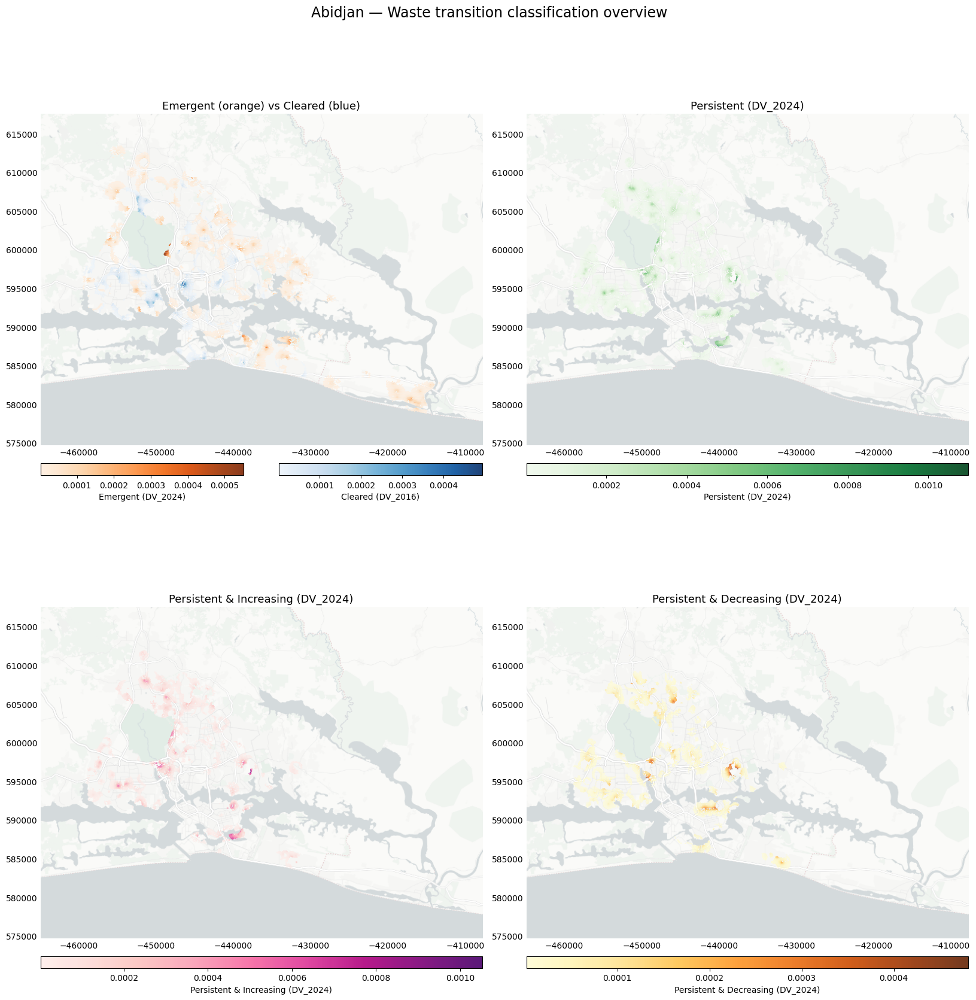

saved: /content/drive/MyDrive/Paper_3/Processing/DV/Combined/Abidjan/Abidjan_classification_overview.png


In [ ]:
def add_bottom_colorbar(ax, hb, label, x0=0.0, width=1.0, y_offset=-0.09, height=0.035):
    cax = ax.inset_axes([x0, y_offset, width, height])
    fig = ax.get_figure()
    fig.colorbar(hb, cax=cax, orientation="horizontal", label=label)

def plot_single_panel(ax, gdf, color_col, cmap, title, bounds):
    xmin, ymin, xmax, ymax = bounds
    padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)

    if len(gdf) == 0:
        ax.set_title(f"{title} (no data)", fontsize=12)
        return
    hb = ax.hexbin(gdf.geometry.x, gdf.geometry.y, C=gdf[color_col],
                    reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1,
                    linewidths=0, alpha=0.9, cmap=cmap, zorder=6)
    add_bottom_colorbar(ax, hb, title)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)
    ax.set_title(title, fontsize=13)

city = "Abidjan"
c = city.lower()
df = pd.read_csv(f"{OUT_BASE}/{city}/{c}_grid30m_combined.csv")

epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())

emergent   = df[df["category"] == "Emergent"].copy()
cleared    = df[df["category"] == "Cleared"].copy()
persistent = df[df["category"].isin(["Increase", "Decrease"])].copy()
increasing = df[df["category"] == "Increase"].copy()
decreasing = df[df["category"] == "Decrease"].copy()

gdf_em = to_web_mercator(emergent, epsg)
gdf_cl = to_web_mercator(cleared, epsg)
gdf_pe = to_web_mercator(persistent, epsg)
gdf_in = to_web_mercator(increasing, epsg)
gdf_de = to_web_mercator(decreasing, epsg)

all_gdf = pd.concat([gdf_em[["geometry"]], gdf_cl[["geometry"]]])
xmin, ymin, xmax, ymax = all_gdf.total_bounds
padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12

fig, axes = plt.subplots(2, 2, figsize=(20, 20))

# --- Panel 1: Emergent vs Cleared (two colour scales, side-by-side bottom bars) ---
ax = axes[0, 0]
ax.set_xlim(xmin - padx, xmax + padx); ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect("equal", adjustable="box")
ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)
if len(gdf_em):
    hb1 = ax.hexbin(gdf_em.geometry.x, gdf_em.geometry.y, C=gdf_em["DV_2024"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=oranges_trunc, zorder=6)
    add_bottom_colorbar(ax, hb1, "Emergent (DV_2024)", x0=0.0, width=0.46)
if len(gdf_cl):
    hb2 = ax.hexbin(gdf_cl.geometry.x, gdf_cl.geometry.y, C=gdf_cl["DV_2016"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=blues_trunc, zorder=6)
    add_bottom_colorbar(ax, hb2, "Cleared (DV_2016)", x0=0.54, width=0.46)
for spine in ax.spines.values(): spine.set_visible(False)
ax.tick_params(axis="both", which="both", length=0)
ax.set_title("Emergent (orange) vs Cleared (blue)", fontsize=13)

# --- Panel 2: Persistent ---
plot_single_panel(axes[0, 1], gdf_pe, "DV_2024", greens_trunc, "Persistent (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 3: Persistent & Increasing ---
plot_single_panel(axes[1, 0], gdf_in, "DV_2024", magenta_trunc, "Persistent & Increasing (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 4: Persistent & Decreasing ---
plot_single_panel(axes[1, 1], gdf_de, "DV_2024", yellows_trunc, "Persistent & Decreasing (DV_2024)", (xmin, ymin, xmax, ymax))

fig.suptitle(f"{city} — Waste transition classification overview", fontsize=17, y=0.93)
plt.subplots_adjust(hspace=0.15, wspace=0.1)

out_dir = f"{OUT_BASE}/{city}"
os.makedirs(out_dir, exist_ok=True)
out_fig = f"{out_dir}/{city}_classification_overview.png"
plt.savefig(out_fig, dpi=250, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved: {out_fig}")

##Accra

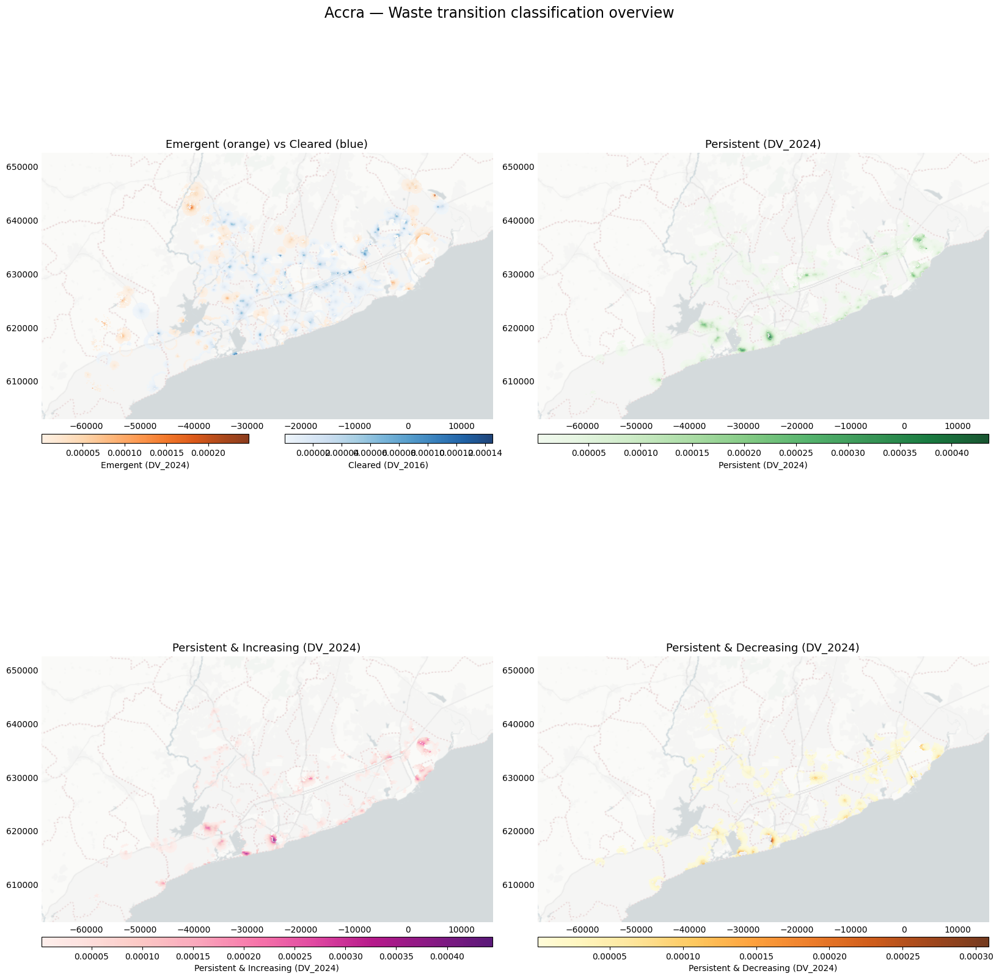

saved: /content/drive/MyDrive/Paper_3/Processing/DV/Combined/Accra/Accra_classification_overview.png


In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import contextily as ctx
import math
import os
from pyproj import CRS, Transformer
import matplotlib.font_manager as fm
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

BASE = "/content/drive/MyDrive/Paper_3/Processing/DV"
OUT_BASE = f"{BASE}/Combined"

GRIDSIZE = 300

CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

oranges_trunc = mcolors.ListedColormap(plt.cm.Oranges(np.linspace(0.05, 1, 256)))
blues_trunc   = mcolors.ListedColormap(plt.cm.Blues(np.linspace(0.05, 1, 256)))
greens_trunc  = mcolors.ListedColormap(plt.cm.Greens(np.linspace(0.05, 1, 256)))
magenta_trunc = mcolors.ListedColormap(plt.cm.RdPu(np.linspace(0.05, 1, 256)))
yellows_trunc = mcolors.ListedColormap(plt.cm.YlOrBr(np.linspace(0.05, 1, 256)))

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

def to_web_mercator(sub_df, epsg):
    g = gpd.GeoDataFrame(
        sub_df, geometry=gpd.points_from_xy(sub_df.longitude, sub_df.latitude), crs=4326
    ).to_crs(epsg).to_crs(3857)
    if len(g) > 100000:
        g = g.sample(100000, random_state=42)
    return g

def add_bottom_colorbar(ax, hb, label, x0=0.0, width=1.0, y_offset=-0.09, height=0.035):
    cax = ax.inset_axes([x0, y_offset, width, height])
    fig = ax.get_figure()
    fig.colorbar(hb, cax=cax, orientation="horizontal", label=label)

def plot_single_panel(ax, gdf, color_col, cmap, title, bounds):
    xmin, ymin, xmax, ymax = bounds
    padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)

    if len(gdf) == 0:
        ax.set_title(f"{title} (no data)", fontsize=12)
        return
    hb = ax.hexbin(gdf.geometry.x, gdf.geometry.y, C=gdf[color_col],
                    reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1,
                    linewidths=0, alpha=0.9, cmap=cmap, zorder=6)
    add_bottom_colorbar(ax, hb, title)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)
    ax.set_title(title, fontsize=13)

def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =====================================================================
# ACCRA
# =====================================================================

city = "Accra"
c = city.lower()
df = pd.read_csv(f"{OUT_BASE}/{city}/{c}_grid30m_combined.csv")

epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())

emergent   = df[df["category"] == "Emergent"].copy()
cleared    = df[df["category"] == "Cleared"].copy()
persistent = df[df["category"].isin(["Increase", "Decrease"])].copy()
increasing = df[df["category"] == "Increase"].copy()
decreasing = df[df["category"] == "Decrease"].copy()

gdf_em = to_web_mercator(emergent, epsg)
gdf_cl = to_web_mercator(cleared, epsg)
gdf_pe = to_web_mercator(persistent, epsg)
gdf_in = to_web_mercator(increasing, epsg)
gdf_de = to_web_mercator(decreasing, epsg)

all_gdf = pd.concat([gdf_em[["geometry"]], gdf_cl[["geometry"]]])
xmin, ymin, xmax, ymax = all_gdf.total_bounds
padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12

fig, axes = plt.subplots(2, 2, figsize=(20, 20))

# --- Panel 1: Emergent vs Cleared (two colour scales, side-by-side bottom bars) ---
ax = axes[0, 0]
ax.set_xlim(xmin - padx, xmax + padx); ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect("equal", adjustable="box")
ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)
if len(gdf_em):
    hb1 = ax.hexbin(gdf_em.geometry.x, gdf_em.geometry.y, C=gdf_em["DV_2024"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=oranges_trunc, zorder=6)
    add_bottom_colorbar(ax, hb1, "Emergent (DV_2024)", x0=0.0, width=0.46)
if len(gdf_cl):
    hb2 = ax.hexbin(gdf_cl.geometry.x, gdf_cl.geometry.y, C=gdf_cl["DV_2016"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=blues_trunc, zorder=6)
    add_bottom_colorbar(ax, hb2, "Cleared (DV_2016)", x0=0.54, width=0.46)
for spine in ax.spines.values(): spine.set_visible(False)
ax.tick_params(axis="both", which="both", length=0)
ax.set_title("Emergent (orange) vs Cleared (blue)", fontsize=13)

# --- Panel 2: Persistent ---
plot_single_panel(axes[0, 1], gdf_pe, "DV_2024", greens_trunc, "Persistent (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 3: Persistent & Increasing ---
plot_single_panel(axes[1, 0], gdf_in, "DV_2024", magenta_trunc, "Persistent & Increasing (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 4: Persistent & Decreasing ---
plot_single_panel(axes[1, 1], gdf_de, "DV_2024", yellows_trunc, "Persistent & Decreasing (DV_2024)", (xmin, ymin, xmax, ymax))

fig.suptitle(f"{city} — Waste transition classification overview", fontsize=17, y=0.93)
plt.subplots_adjust(hspace=0.15, wspace=0.1)

out_dir = f"{OUT_BASE}/{city}"
os.makedirs(out_dir, exist_ok=True)
out_fig = f"{out_dir}/{city}_classification_overview.png"
plt.savefig(out_fig, dpi=250, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved: {out_fig}")

##Dakar

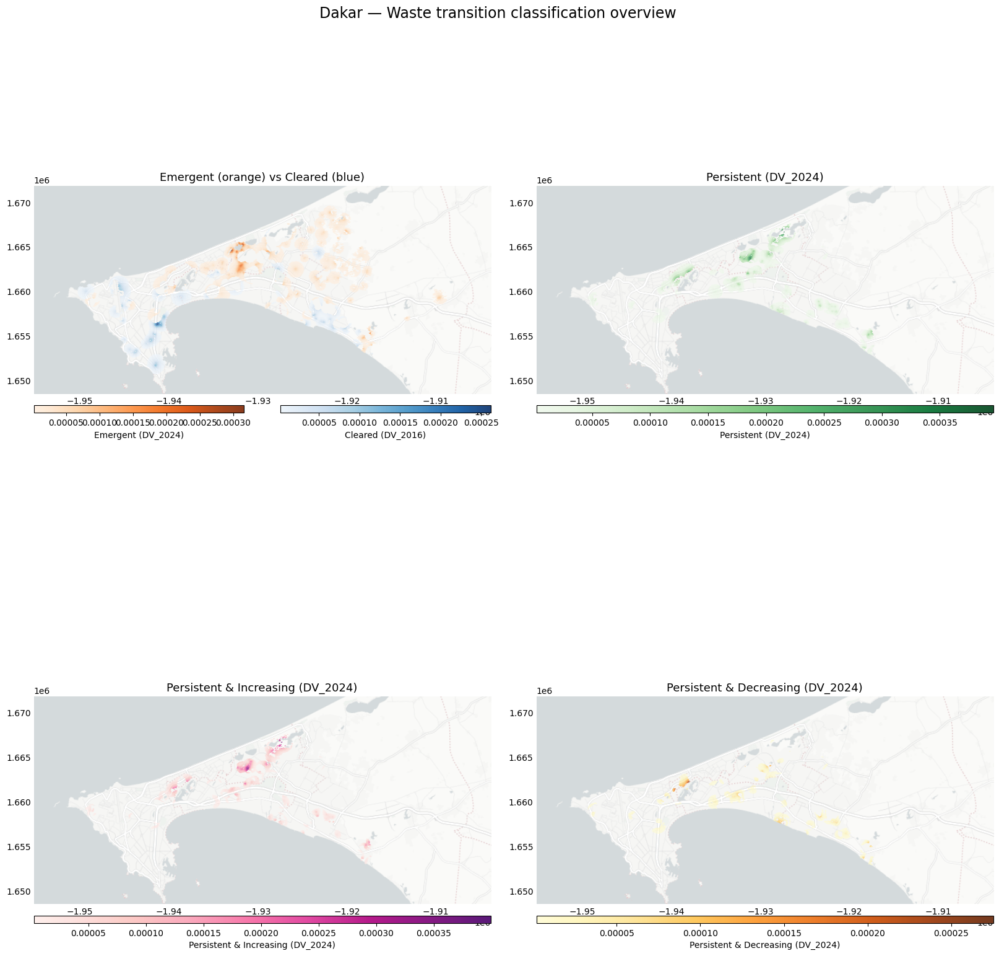

saved: /content/drive/MyDrive/Paper_3/Processing/DV/Combined/Dakar/Dakar_classification_overview.png


In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import contextily as ctx
import math
import os
from pyproj import CRS, Transformer
import matplotlib.font_manager as fm
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

BASE = "/content/drive/MyDrive/Paper_3/Processing/DV"
OUT_BASE = f"{BASE}/Combined"

GRIDSIZE = 300

CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

oranges_trunc = mcolors.ListedColormap(plt.cm.Oranges(np.linspace(0.05, 1, 256)))
blues_trunc   = mcolors.ListedColormap(plt.cm.Blues(np.linspace(0.05, 1, 256)))
greens_trunc  = mcolors.ListedColormap(plt.cm.Greens(np.linspace(0.05, 1, 256)))
magenta_trunc = mcolors.ListedColormap(plt.cm.RdPu(np.linspace(0.05, 1, 256)))
yellows_trunc = mcolors.ListedColormap(plt.cm.YlOrBr(np.linspace(0.05, 1, 256)))

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

def to_web_mercator(sub_df, epsg):
    g = gpd.GeoDataFrame(
        sub_df, geometry=gpd.points_from_xy(sub_df.longitude, sub_df.latitude), crs=4326
    ).to_crs(epsg).to_crs(3857)
    if len(g) > 100000:
        g = g.sample(100000, random_state=42)
    return g

def add_bottom_colorbar(ax, hb, label, x0=0.0, width=1.0, y_offset=-0.09, height=0.035):
    cax = ax.inset_axes([x0, y_offset, width, height])
    fig = ax.get_figure()
    fig.colorbar(hb, cax=cax, orientation="horizontal", label=label)

def plot_single_panel(ax, gdf, color_col, cmap, title, bounds):
    xmin, ymin, xmax, ymax = bounds
    padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)

    if len(gdf) == 0:
        ax.set_title(f"{title} (no data)", fontsize=12)
        return
    hb = ax.hexbin(gdf.geometry.x, gdf.geometry.y, C=gdf[color_col],
                    reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1,
                    linewidths=0, alpha=0.9, cmap=cmap, zorder=6)
    add_bottom_colorbar(ax, hb, title)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)
    ax.set_title(title, fontsize=13)

def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =====================================================================
# Dakar
# =====================================================================

city = "Dakar"
c = city.lower()
df = pd.read_csv(f"{OUT_BASE}/{city}/{c}_grid30m_combined.csv")

epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())

emergent   = df[df["category"] == "Emergent"].copy()
cleared    = df[df["category"] == "Cleared"].copy()
persistent = df[df["category"].isin(["Increase", "Decrease"])].copy()
increasing = df[df["category"] == "Increase"].copy()
decreasing = df[df["category"] == "Decrease"].copy()

gdf_em = to_web_mercator(emergent, epsg)
gdf_cl = to_web_mercator(cleared, epsg)
gdf_pe = to_web_mercator(persistent, epsg)
gdf_in = to_web_mercator(increasing, epsg)
gdf_de = to_web_mercator(decreasing, epsg)

all_gdf = pd.concat([gdf_em[["geometry"]], gdf_cl[["geometry"]]])
xmin, ymin, xmax, ymax = all_gdf.total_bounds
padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12

fig, axes = plt.subplots(2, 2, figsize=(20, 20))

# --- Panel 1: Emergent vs Cleared (two colour scales, side-by-side bottom bars) ---
ax = axes[0, 0]
ax.set_xlim(xmin - padx, xmax + padx); ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect("equal", adjustable="box")
ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)
if len(gdf_em):
    hb1 = ax.hexbin(gdf_em.geometry.x, gdf_em.geometry.y, C=gdf_em["DV_2024"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=oranges_trunc, zorder=6)
    add_bottom_colorbar(ax, hb1, "Emergent (DV_2024)", x0=0.0, width=0.46)
if len(gdf_cl):
    hb2 = ax.hexbin(gdf_cl.geometry.x, gdf_cl.geometry.y, C=gdf_cl["DV_2016"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=blues_trunc, zorder=6)
    add_bottom_colorbar(ax, hb2, "Cleared (DV_2016)", x0=0.54, width=0.46)
for spine in ax.spines.values(): spine.set_visible(False)
ax.tick_params(axis="both", which="both", length=0)
ax.set_title("Emergent (orange) vs Cleared (blue)", fontsize=13)

# --- Panel 2: Persistent ---
plot_single_panel(axes[0, 1], gdf_pe, "DV_2024", greens_trunc, "Persistent (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 3: Persistent & Increasing ---
plot_single_panel(axes[1, 0], gdf_in, "DV_2024", magenta_trunc, "Persistent & Increasing (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 4: Persistent & Decreasing ---
plot_single_panel(axes[1, 1], gdf_de, "DV_2024", yellows_trunc, "Persistent & Decreasing (DV_2024)", (xmin, ymin, xmax, ymax))

fig.suptitle(f"{city} — Waste transition classification overview", fontsize=17, y=0.93)
plt.subplots_adjust(hspace=0.15, wspace=0.1)

out_dir = f"{OUT_BASE}/{city}"
os.makedirs(out_dir, exist_ok=True)
out_fig = f"{out_dir}/{city}_classification_overview.png"
plt.savefig(out_fig, dpi=250, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved: {out_fig}")

##Freetown

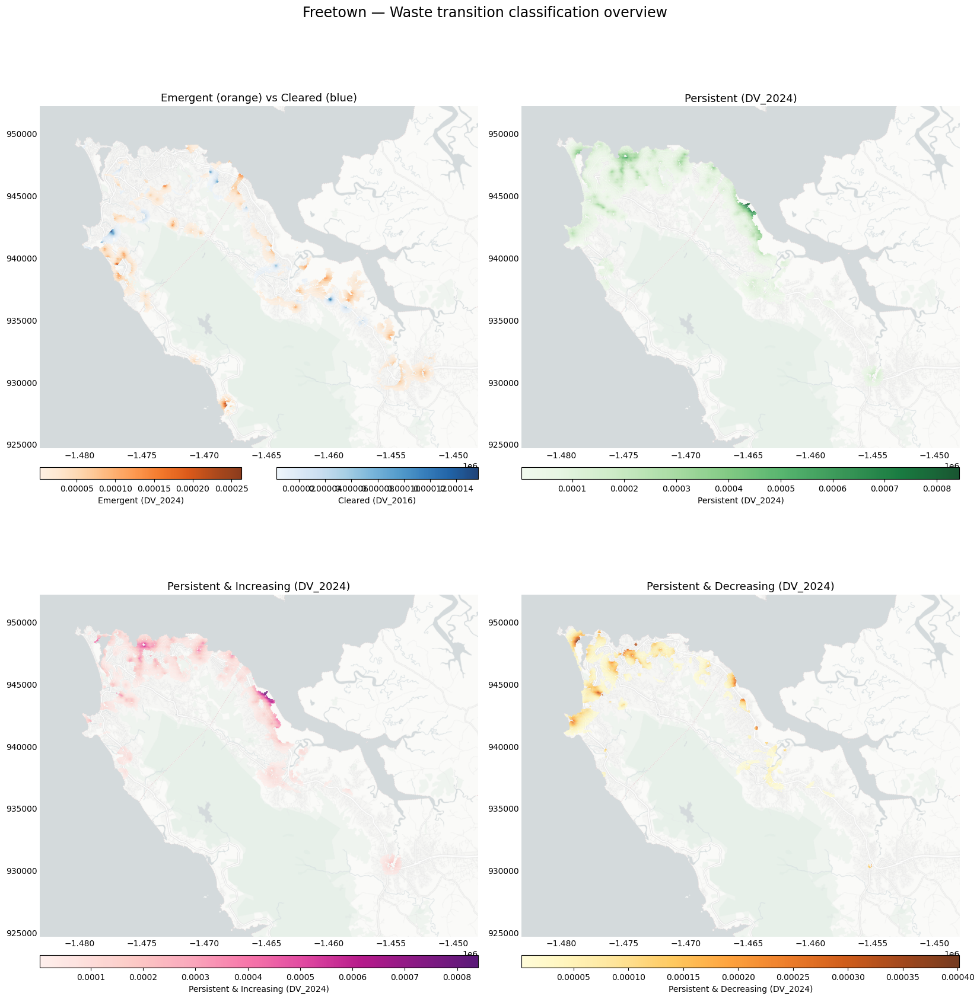

saved: /content/drive/MyDrive/Paper_3/Processing/DV/Combined/Freetown/Freetown_classification_overview.png


In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import contextily as ctx
import math
import os
from pyproj import CRS, Transformer
import matplotlib.font_manager as fm
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

BASE = "/content/drive/MyDrive/Paper_3/Processing/DV"
OUT_BASE = f"{BASE}/Combined"

GRIDSIZE = 300

CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

oranges_trunc = mcolors.ListedColormap(plt.cm.Oranges(np.linspace(0.05, 1, 256)))
blues_trunc   = mcolors.ListedColormap(plt.cm.Blues(np.linspace(0.05, 1, 256)))
greens_trunc  = mcolors.ListedColormap(plt.cm.Greens(np.linspace(0.05, 1, 256)))
magenta_trunc = mcolors.ListedColormap(plt.cm.RdPu(np.linspace(0.05, 1, 256)))
yellows_trunc = mcolors.ListedColormap(plt.cm.YlOrBr(np.linspace(0.05, 1, 256)))

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

def to_web_mercator(sub_df, epsg):
    g = gpd.GeoDataFrame(
        sub_df, geometry=gpd.points_from_xy(sub_df.longitude, sub_df.latitude), crs=4326
    ).to_crs(epsg).to_crs(3857)
    if len(g) > 100000:
        g = g.sample(100000, random_state=42)
    return g

def add_bottom_colorbar(ax, hb, label, x0=0.0, width=1.0, y_offset=-0.09, height=0.035):
    cax = ax.inset_axes([x0, y_offset, width, height])
    fig = ax.get_figure()
    fig.colorbar(hb, cax=cax, orientation="horizontal", label=label)

def plot_single_panel(ax, gdf, color_col, cmap, title, bounds):
    xmin, ymin, xmax, ymax = bounds
    padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)

    if len(gdf) == 0:
        ax.set_title(f"{title} (no data)", fontsize=12)
        return
    hb = ax.hexbin(gdf.geometry.x, gdf.geometry.y, C=gdf[color_col],
                    reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1,
                    linewidths=0, alpha=0.9, cmap=cmap, zorder=6)
    add_bottom_colorbar(ax, hb, title)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)
    ax.set_title(title, fontsize=13)

def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =====================================================================
# FREETOWN
# =====================================================================

city = "Freetown"
c = city.lower()
df = pd.read_csv(f"{OUT_BASE}/{city}/{c}_grid30m_combined.csv")

epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())

emergent   = df[df["category"] == "Emergent"].copy()
cleared    = df[df["category"] == "Cleared"].copy()
persistent = df[df["category"].isin(["Increase", "Decrease"])].copy()
increasing = df[df["category"] == "Increase"].copy()
decreasing = df[df["category"] == "Decrease"].copy()

gdf_em = to_web_mercator(emergent, epsg)
gdf_cl = to_web_mercator(cleared, epsg)
gdf_pe = to_web_mercator(persistent, epsg)
gdf_in = to_web_mercator(increasing, epsg)
gdf_de = to_web_mercator(decreasing, epsg)

all_gdf = pd.concat([gdf_em[["geometry"]], gdf_cl[["geometry"]]])
xmin, ymin, xmax, ymax = all_gdf.total_bounds
padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12

fig, axes = plt.subplots(2, 2, figsize=(20, 20))

# --- Panel 1: Emergent vs Cleared (two colour scales, side-by-side bottom bars) ---
ax = axes[0, 0]
ax.set_xlim(xmin - padx, xmax + padx); ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect("equal", adjustable="box")
ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)
if len(gdf_em):
    hb1 = ax.hexbin(gdf_em.geometry.x, gdf_em.geometry.y, C=gdf_em["DV_2024"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=oranges_trunc, zorder=6)
    add_bottom_colorbar(ax, hb1, "Emergent (DV_2024)", x0=0.0, width=0.46)
if len(gdf_cl):
    hb2 = ax.hexbin(gdf_cl.geometry.x, gdf_cl.geometry.y, C=gdf_cl["DV_2016"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=blues_trunc, zorder=6)
    add_bottom_colorbar(ax, hb2, "Cleared (DV_2016)", x0=0.54, width=0.46)
for spine in ax.spines.values(): spine.set_visible(False)
ax.tick_params(axis="both", which="both", length=0)
ax.set_title("Emergent (orange) vs Cleared (blue)", fontsize=13)

# --- Panel 2: Persistent ---
plot_single_panel(axes[0, 1], gdf_pe, "DV_2024", greens_trunc, "Persistent (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 3: Persistent & Increasing ---
plot_single_panel(axes[1, 0], gdf_in, "DV_2024", magenta_trunc, "Persistent & Increasing (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 4: Persistent & Decreasing ---
plot_single_panel(axes[1, 1], gdf_de, "DV_2024", yellows_trunc, "Persistent & Decreasing (DV_2024)", (xmin, ymin, xmax, ymax))

fig.suptitle(f"{city} — Waste transition classification overview", fontsize=17, y=0.93)
plt.subplots_adjust(hspace=0.15, wspace=0.1)

out_dir = f"{OUT_BASE}/{city}"
os.makedirs(out_dir, exist_ok=True)
out_fig = f"{out_dir}/{city}_classification_overview.png"
plt.savefig(out_fig, dpi=250, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved: {out_fig}")

##Johannesburg

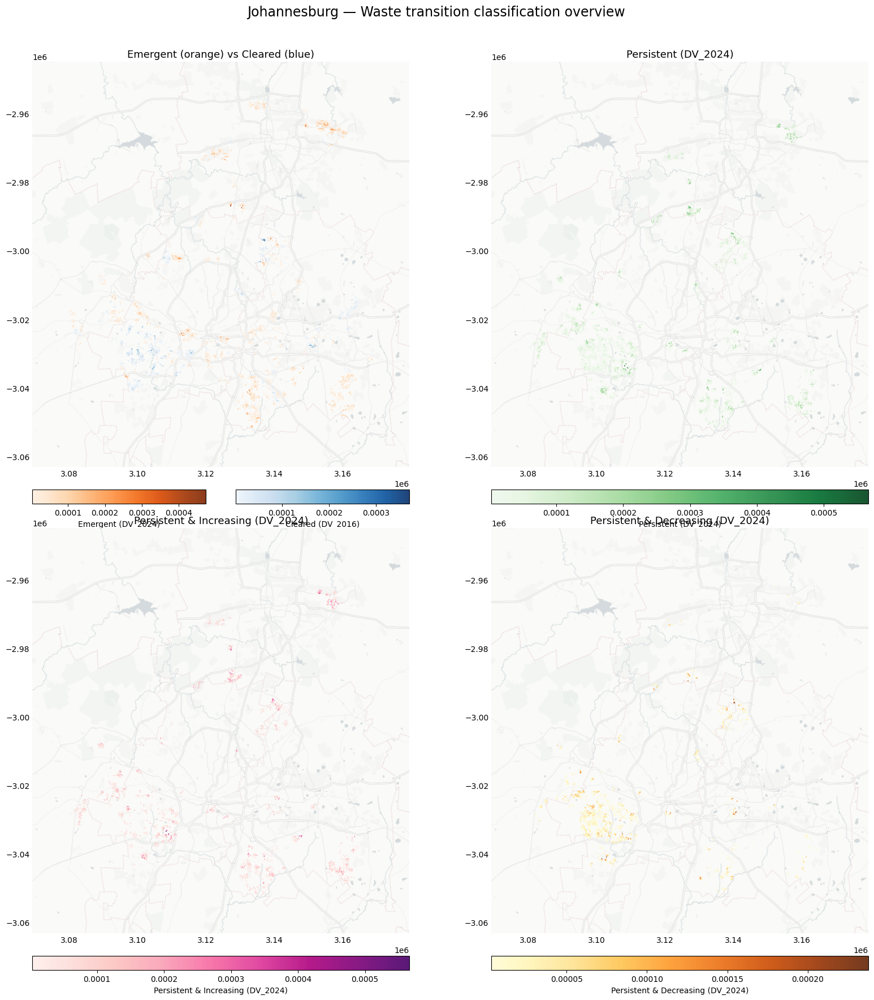

saved: /content/drive/MyDrive/Paper_3/Processing/DV/Combined/Johannesburg/Johannesburg_classification_overview.png


In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import contextily as ctx
import math
import os
from pyproj import CRS, Transformer
import matplotlib.font_manager as fm
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

BASE = "/content/drive/MyDrive/Paper_3/Processing/DV"
OUT_BASE = f"{BASE}/Combined"

GRIDSIZE = 300

CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

oranges_trunc = mcolors.ListedColormap(plt.cm.Oranges(np.linspace(0.05, 1, 256)))
blues_trunc   = mcolors.ListedColormap(plt.cm.Blues(np.linspace(0.05, 1, 256)))
greens_trunc  = mcolors.ListedColormap(plt.cm.Greens(np.linspace(0.05, 1, 256)))
magenta_trunc = mcolors.ListedColormap(plt.cm.RdPu(np.linspace(0.05, 1, 256)))
yellows_trunc = mcolors.ListedColormap(plt.cm.YlOrBr(np.linspace(0.05, 1, 256)))

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

def to_web_mercator(sub_df, epsg):
    g = gpd.GeoDataFrame(
        sub_df, geometry=gpd.points_from_xy(sub_df.longitude, sub_df.latitude), crs=4326
    ).to_crs(epsg).to_crs(3857)
    if len(g) > 100000:
        g = g.sample(100000, random_state=42)
    return g

def add_bottom_colorbar(ax, hb, label, x0=0.0, width=1.0, y_offset=-0.09, height=0.035):
    cax = ax.inset_axes([x0, y_offset, width, height])
    fig = ax.get_figure()
    fig.colorbar(hb, cax=cax, orientation="horizontal", label=label)

def plot_single_panel(ax, gdf, color_col, cmap, title, bounds):
    xmin, ymin, xmax, ymax = bounds
    padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)

    if len(gdf) == 0:
        ax.set_title(f"{title} (no data)", fontsize=12)
        return
    hb = ax.hexbin(gdf.geometry.x, gdf.geometry.y, C=gdf[color_col],
                    reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1,
                    linewidths=0, alpha=0.9, cmap=cmap, zorder=6)
    add_bottom_colorbar(ax, hb, title)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)
    ax.set_title(title, fontsize=13)

def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =====================================================================
# JOHANNESBURG
# =====================================================================

city = "Johannesburg"
c = city.lower()
df = pd.read_csv(f"{OUT_BASE}/{city}/{c}_grid30m_combined.csv")

epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())

emergent   = df[df["category"] == "Emergent"].copy()
cleared    = df[df["category"] == "Cleared"].copy()
persistent = df[df["category"].isin(["Increase", "Decrease"])].copy()
increasing = df[df["category"] == "Increase"].copy()
decreasing = df[df["category"] == "Decrease"].copy()

gdf_em = to_web_mercator(emergent, epsg)
gdf_cl = to_web_mercator(cleared, epsg)
gdf_pe = to_web_mercator(persistent, epsg)
gdf_in = to_web_mercator(increasing, epsg)
gdf_de = to_web_mercator(decreasing, epsg)

all_gdf = pd.concat([gdf_em[["geometry"]], gdf_cl[["geometry"]]])
xmin, ymin, xmax, ymax = all_gdf.total_bounds
padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12

fig, axes = plt.subplots(2, 2, figsize=(20, 20))

# --- Panel 1: Emergent vs Cleared (two colour scales, side-by-side bottom bars) ---
ax = axes[0, 0]
ax.set_xlim(xmin - padx, xmax + padx); ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect("equal", adjustable="box")
ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)
if len(gdf_em):
    hb1 = ax.hexbin(gdf_em.geometry.x, gdf_em.geometry.y, C=gdf_em["DV_2024"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=oranges_trunc, zorder=6)
    add_bottom_colorbar(ax, hb1, "Emergent (DV_2024)", x0=0.0, width=0.46)
if len(gdf_cl):
    hb2 = ax.hexbin(gdf_cl.geometry.x, gdf_cl.geometry.y, C=gdf_cl["DV_2016"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=blues_trunc, zorder=6)
    add_bottom_colorbar(ax, hb2, "Cleared (DV_2016)", x0=0.54, width=0.46)
for spine in ax.spines.values(): spine.set_visible(False)
ax.tick_params(axis="both", which="both", length=0)
ax.set_title("Emergent (orange) vs Cleared (blue)", fontsize=13)

# --- Panel 2: Persistent ---
plot_single_panel(axes[0, 1], gdf_pe, "DV_2024", greens_trunc, "Persistent (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 3: Persistent & Increasing ---
plot_single_panel(axes[1, 0], gdf_in, "DV_2024", magenta_trunc, "Persistent & Increasing (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 4: Persistent & Decreasing ---
plot_single_panel(axes[1, 1], gdf_de, "DV_2024", yellows_trunc, "Persistent & Decreasing (DV_2024)", (xmin, ymin, xmax, ymax))

fig.suptitle(f"{city} — Waste transition classification overview", fontsize=17, y=0.93)
plt.subplots_adjust(hspace=0.15, wspace=0.1)

out_dir = f"{OUT_BASE}/{city}"
os.makedirs(out_dir, exist_ok=True)
out_fig = f"{out_dir}/{city}_classification_overview.png"
plt.savefig(out_fig, dpi=250, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved: {out_fig}")

##Kampala

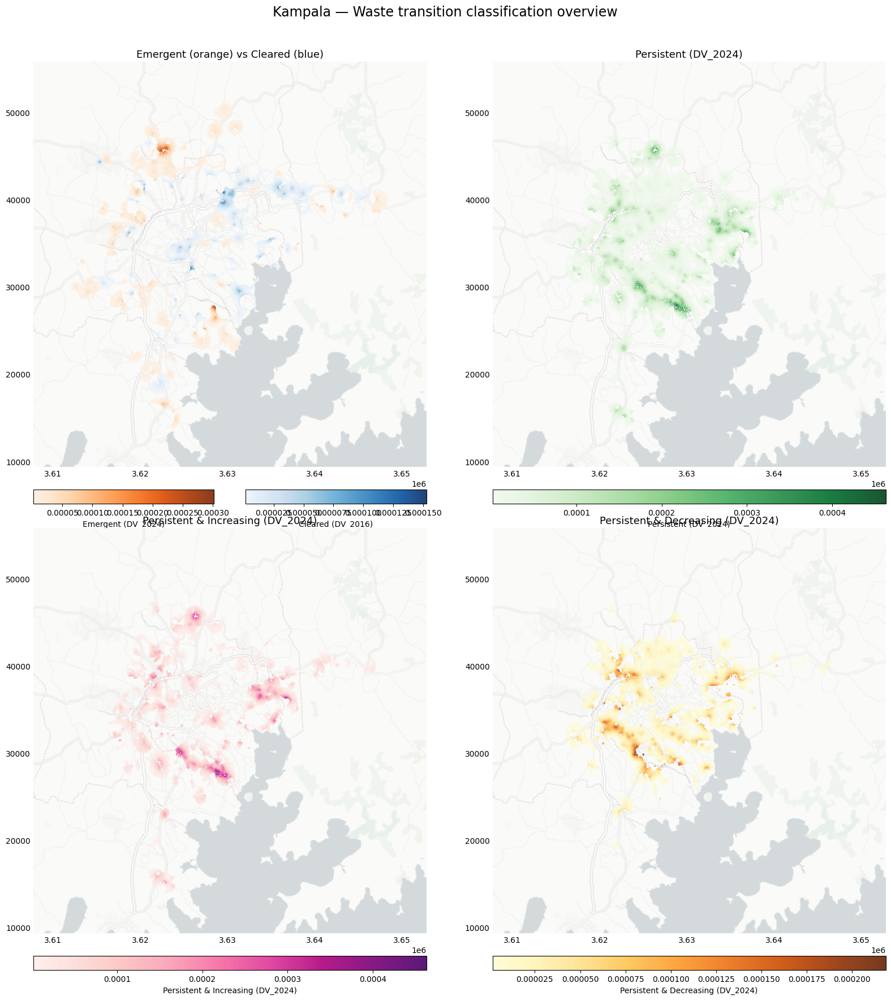

saved: /content/drive/MyDrive/Paper_3/Processing/DV/Combined/Kampala/Kampala_classification_overview.png


In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import contextily as ctx
import math
import os
from pyproj import CRS, Transformer
import matplotlib.font_manager as fm
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

BASE = "/content/drive/MyDrive/Paper_3/Processing/DV"
OUT_BASE = f"{BASE}/Combined"

GRIDSIZE = 300

CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

oranges_trunc = mcolors.ListedColormap(plt.cm.Oranges(np.linspace(0.05, 1, 256)))
blues_trunc   = mcolors.ListedColormap(plt.cm.Blues(np.linspace(0.05, 1, 256)))
greens_trunc  = mcolors.ListedColormap(plt.cm.Greens(np.linspace(0.05, 1, 256)))
magenta_trunc = mcolors.ListedColormap(plt.cm.RdPu(np.linspace(0.05, 1, 256)))
yellows_trunc = mcolors.ListedColormap(plt.cm.YlOrBr(np.linspace(0.05, 1, 256)))

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

def to_web_mercator(sub_df, epsg):
    g = gpd.GeoDataFrame(
        sub_df, geometry=gpd.points_from_xy(sub_df.longitude, sub_df.latitude), crs=4326
    ).to_crs(epsg).to_crs(3857)
    if len(g) > 100000:
        g = g.sample(100000, random_state=42)
    return g

def add_bottom_colorbar(ax, hb, label, x0=0.0, width=1.0, y_offset=-0.09, height=0.035):
    cax = ax.inset_axes([x0, y_offset, width, height])
    fig = ax.get_figure()
    fig.colorbar(hb, cax=cax, orientation="horizontal", label=label)

def plot_single_panel(ax, gdf, color_col, cmap, title, bounds):
    xmin, ymin, xmax, ymax = bounds
    padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)

    if len(gdf) == 0:
        ax.set_title(f"{title} (no data)", fontsize=12)
        return
    hb = ax.hexbin(gdf.geometry.x, gdf.geometry.y, C=gdf[color_col],
                    reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1,
                    linewidths=0, alpha=0.9, cmap=cmap, zorder=6)
    add_bottom_colorbar(ax, hb, title)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)
    ax.set_title(title, fontsize=13)

def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =====================================================================
# KAMPALA
# =====================================================================

city = "Kampala"
c = city.lower()
df = pd.read_csv(f"{OUT_BASE}/{city}/{c}_grid30m_combined.csv")

epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())

emergent   = df[df["category"] == "Emergent"].copy()
cleared    = df[df["category"] == "Cleared"].copy()
persistent = df[df["category"].isin(["Increase", "Decrease"])].copy()
increasing = df[df["category"] == "Increase"].copy()
decreasing = df[df["category"] == "Decrease"].copy()

gdf_em = to_web_mercator(emergent, epsg)
gdf_cl = to_web_mercator(cleared, epsg)
gdf_pe = to_web_mercator(persistent, epsg)
gdf_in = to_web_mercator(increasing, epsg)
gdf_de = to_web_mercator(decreasing, epsg)

all_gdf = pd.concat([gdf_em[["geometry"]], gdf_cl[["geometry"]]])
xmin, ymin, xmax, ymax = all_gdf.total_bounds
padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12

fig, axes = plt.subplots(2, 2, figsize=(20, 20))

# --- Panel 1: Emergent vs Cleared (two colour scales, side-by-side bottom bars) ---
ax = axes[0, 0]
ax.set_xlim(xmin - padx, xmax + padx); ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect("equal", adjustable="box")
ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)
if len(gdf_em):
    hb1 = ax.hexbin(gdf_em.geometry.x, gdf_em.geometry.y, C=gdf_em["DV_2024"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=oranges_trunc, zorder=6)
    add_bottom_colorbar(ax, hb1, "Emergent (DV_2024)", x0=0.0, width=0.46)
if len(gdf_cl):
    hb2 = ax.hexbin(gdf_cl.geometry.x, gdf_cl.geometry.y, C=gdf_cl["DV_2016"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=blues_trunc, zorder=6)
    add_bottom_colorbar(ax, hb2, "Cleared (DV_2016)", x0=0.54, width=0.46)
for spine in ax.spines.values(): spine.set_visible(False)
ax.tick_params(axis="both", which="both", length=0)
ax.set_title("Emergent (orange) vs Cleared (blue)", fontsize=13)

# --- Panel 2: Persistent ---
plot_single_panel(axes[0, 1], gdf_pe, "DV_2024", greens_trunc, "Persistent (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 3: Persistent & Increasing ---
plot_single_panel(axes[1, 0], gdf_in, "DV_2024", magenta_trunc, "Persistent & Increasing (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 4: Persistent & Decreasing ---
plot_single_panel(axes[1, 1], gdf_de, "DV_2024", yellows_trunc, "Persistent & Decreasing (DV_2024)", (xmin, ymin, xmax, ymax))

fig.suptitle(f"{city} — Waste transition classification overview", fontsize=17, y=0.93)
plt.subplots_adjust(hspace=0.15, wspace=0.1)

out_dir = f"{OUT_BASE}/{city}"
os.makedirs(out_dir, exist_ok=True)
out_fig = f"{out_dir}/{city}_classification_overview.png"
plt.savefig(out_fig, dpi=250, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved: {out_fig}")

##Kinshasa

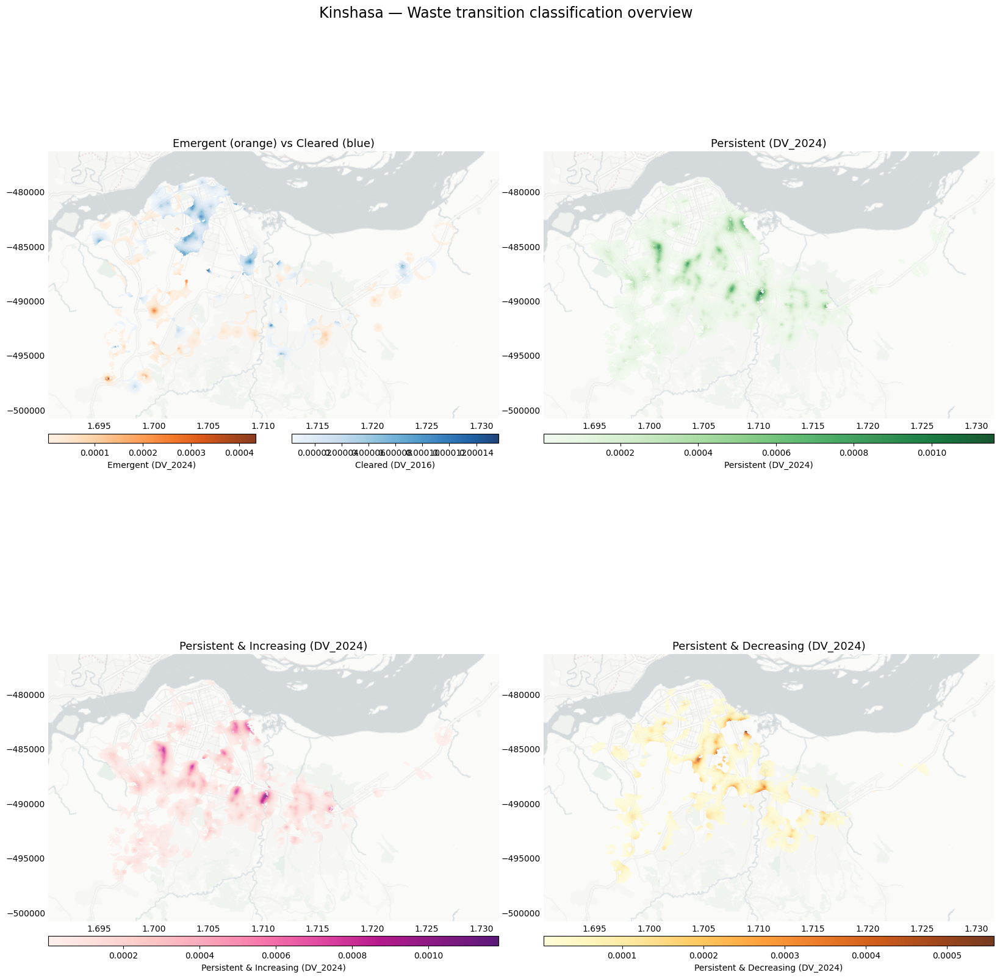

saved: /content/drive/MyDrive/Paper_3/Processing/DV/Combined/Kinshasa/Kinshasa_classification_overview.png


In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import contextily as ctx
import math
import os
from pyproj import CRS, Transformer
import matplotlib.font_manager as fm
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

BASE = "/content/drive/MyDrive/Paper_3/Processing/DV"
OUT_BASE = f"{BASE}/Combined"

GRIDSIZE = 300

CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

oranges_trunc = mcolors.ListedColormap(plt.cm.Oranges(np.linspace(0.05, 1, 256)))
blues_trunc   = mcolors.ListedColormap(plt.cm.Blues(np.linspace(0.05, 1, 256)))
greens_trunc  = mcolors.ListedColormap(plt.cm.Greens(np.linspace(0.05, 1, 256)))
magenta_trunc = mcolors.ListedColormap(plt.cm.RdPu(np.linspace(0.05, 1, 256)))
yellows_trunc = mcolors.ListedColormap(plt.cm.YlOrBr(np.linspace(0.05, 1, 256)))

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

def to_web_mercator(sub_df, epsg):
    g = gpd.GeoDataFrame(
        sub_df, geometry=gpd.points_from_xy(sub_df.longitude, sub_df.latitude), crs=4326
    ).to_crs(epsg).to_crs(3857)
    if len(g) > 100000:
        g = g.sample(100000, random_state=42)
    return g

def add_bottom_colorbar(ax, hb, label, x0=0.0, width=1.0, y_offset=-0.09, height=0.035):
    cax = ax.inset_axes([x0, y_offset, width, height])
    fig = ax.get_figure()
    fig.colorbar(hb, cax=cax, orientation="horizontal", label=label)

def plot_single_panel(ax, gdf, color_col, cmap, title, bounds):
    xmin, ymin, xmax, ymax = bounds
    padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)

    if len(gdf) == 0:
        ax.set_title(f"{title} (no data)", fontsize=12)
        return
    hb = ax.hexbin(gdf.geometry.x, gdf.geometry.y, C=gdf[color_col],
                    reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1,
                    linewidths=0, alpha=0.9, cmap=cmap, zorder=6)
    add_bottom_colorbar(ax, hb, title)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)
    ax.set_title(title, fontsize=13)

def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =====================================================================
# KINSHASA
# =====================================================================

city = "Kinshasa"
c = city.lower()
df = pd.read_csv(f"{OUT_BASE}/{city}/{c}_grid30m_combined.csv")

epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())

emergent   = df[df["category"] == "Emergent"].copy()
cleared    = df[df["category"] == "Cleared"].copy()
persistent = df[df["category"].isin(["Increase", "Decrease"])].copy()
increasing = df[df["category"] == "Increase"].copy()
decreasing = df[df["category"] == "Decrease"].copy()

gdf_em = to_web_mercator(emergent, epsg)
gdf_cl = to_web_mercator(cleared, epsg)
gdf_pe = to_web_mercator(persistent, epsg)
gdf_in = to_web_mercator(increasing, epsg)
gdf_de = to_web_mercator(decreasing, epsg)

all_gdf = pd.concat([gdf_em[["geometry"]], gdf_cl[["geometry"]]])
xmin, ymin, xmax, ymax = all_gdf.total_bounds
padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12

fig, axes = plt.subplots(2, 2, figsize=(20, 20))

# --- Panel 1: Emergent vs Cleared (two colour scales, side-by-side bottom bars) ---
ax = axes[0, 0]
ax.set_xlim(xmin - padx, xmax + padx); ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect("equal", adjustable="box")
ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)
if len(gdf_em):
    hb1 = ax.hexbin(gdf_em.geometry.x, gdf_em.geometry.y, C=gdf_em["DV_2024"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=oranges_trunc, zorder=6)
    add_bottom_colorbar(ax, hb1, "Emergent (DV_2024)", x0=0.0, width=0.46)
if len(gdf_cl):
    hb2 = ax.hexbin(gdf_cl.geometry.x, gdf_cl.geometry.y, C=gdf_cl["DV_2016"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=blues_trunc, zorder=6)
    add_bottom_colorbar(ax, hb2, "Cleared (DV_2016)", x0=0.54, width=0.46)
for spine in ax.spines.values(): spine.set_visible(False)
ax.tick_params(axis="both", which="both", length=0)
ax.set_title("Emergent (orange) vs Cleared (blue)", fontsize=13)

# --- Panel 2: Persistent ---
plot_single_panel(axes[0, 1], gdf_pe, "DV_2024", greens_trunc, "Persistent (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 3: Persistent & Increasing ---
plot_single_panel(axes[1, 0], gdf_in, "DV_2024", magenta_trunc, "Persistent & Increasing (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 4: Persistent & Decreasing ---
plot_single_panel(axes[1, 1], gdf_de, "DV_2024", yellows_trunc, "Persistent & Decreasing (DV_2024)", (xmin, ymin, xmax, ymax))

fig.suptitle(f"{city} — Waste transition classification overview", fontsize=17, y=0.93)
plt.subplots_adjust(hspace=0.15, wspace=0.1)

out_dir = f"{OUT_BASE}/{city}"
os.makedirs(out_dir, exist_ok=True)
out_fig = f"{out_dir}/{city}_classification_overview.png"
plt.savefig(out_fig, dpi=250, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved: {out_fig}")

##Lagos

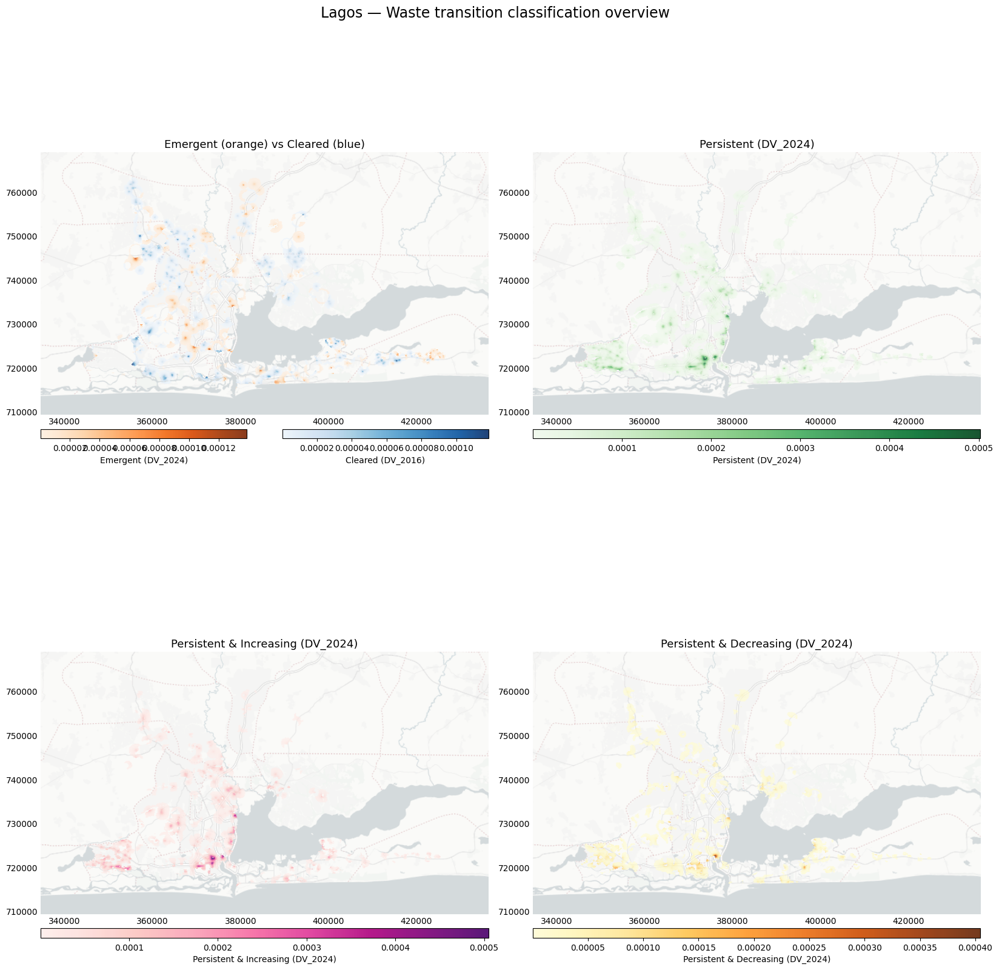

saved: /content/drive/MyDrive/Paper_3/Processing/DV/Combined/Lagos/Lagos_classification_overview.png


In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import contextily as ctx
import math
import os
from pyproj import CRS, Transformer
import matplotlib.font_manager as fm
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

BASE = "/content/drive/MyDrive/Paper_3/Processing/DV"
OUT_BASE = f"{BASE}/Combined"

GRIDSIZE = 300

CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

oranges_trunc = mcolors.ListedColormap(plt.cm.Oranges(np.linspace(0.05, 1, 256)))
blues_trunc   = mcolors.ListedColormap(plt.cm.Blues(np.linspace(0.05, 1, 256)))
greens_trunc  = mcolors.ListedColormap(plt.cm.Greens(np.linspace(0.05, 1, 256)))
magenta_trunc = mcolors.ListedColormap(plt.cm.RdPu(np.linspace(0.05, 1, 256)))
yellows_trunc = mcolors.ListedColormap(plt.cm.YlOrBr(np.linspace(0.05, 1, 256)))

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

def to_web_mercator(sub_df, epsg):
    g = gpd.GeoDataFrame(
        sub_df, geometry=gpd.points_from_xy(sub_df.longitude, sub_df.latitude), crs=4326
    ).to_crs(epsg).to_crs(3857)
    if len(g) > 100000:
        g = g.sample(100000, random_state=42)
    return g

def add_bottom_colorbar(ax, hb, label, x0=0.0, width=1.0, y_offset=-0.09, height=0.035):
    cax = ax.inset_axes([x0, y_offset, width, height])
    fig = ax.get_figure()
    fig.colorbar(hb, cax=cax, orientation="horizontal", label=label)

def plot_single_panel(ax, gdf, color_col, cmap, title, bounds):
    xmin, ymin, xmax, ymax = bounds
    padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)

    if len(gdf) == 0:
        ax.set_title(f"{title} (no data)", fontsize=12)
        return
    hb = ax.hexbin(gdf.geometry.x, gdf.geometry.y, C=gdf[color_col],
                    reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1,
                    linewidths=0, alpha=0.9, cmap=cmap, zorder=6)
    add_bottom_colorbar(ax, hb, title)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)
    ax.set_title(title, fontsize=13)

def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =====================================================================
# LAGOS
# =====================================================================

city = "Lagos"
c = city.lower()
df = pd.read_csv(f"{OUT_BASE}/{city}/{c}_grid30m_combined.csv")

epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())

emergent   = df[df["category"] == "Emergent"].copy()
cleared    = df[df["category"] == "Cleared"].copy()
persistent = df[df["category"].isin(["Increase", "Decrease"])].copy()
increasing = df[df["category"] == "Increase"].copy()
decreasing = df[df["category"] == "Decrease"].copy()

gdf_em = to_web_mercator(emergent, epsg)
gdf_cl = to_web_mercator(cleared, epsg)
gdf_pe = to_web_mercator(persistent, epsg)
gdf_in = to_web_mercator(increasing, epsg)
gdf_de = to_web_mercator(decreasing, epsg)

all_gdf = pd.concat([gdf_em[["geometry"]], gdf_cl[["geometry"]]])
xmin, ymin, xmax, ymax = all_gdf.total_bounds
padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12

fig, axes = plt.subplots(2, 2, figsize=(20, 20))

# --- Panel 1: Emergent vs Cleared (two colour scales, side-by-side bottom bars) ---
ax = axes[0, 0]
ax.set_xlim(xmin - padx, xmax + padx); ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect("equal", adjustable="box")
ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)
if len(gdf_em):
    hb1 = ax.hexbin(gdf_em.geometry.x, gdf_em.geometry.y, C=gdf_em["DV_2024"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=oranges_trunc, zorder=6)
    add_bottom_colorbar(ax, hb1, "Emergent (DV_2024)", x0=0.0, width=0.46)
if len(gdf_cl):
    hb2 = ax.hexbin(gdf_cl.geometry.x, gdf_cl.geometry.y, C=gdf_cl["DV_2016"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=blues_trunc, zorder=6)
    add_bottom_colorbar(ax, hb2, "Cleared (DV_2016)", x0=0.54, width=0.46)
for spine in ax.spines.values(): spine.set_visible(False)
ax.tick_params(axis="both", which="both", length=0)
ax.set_title("Emergent (orange) vs Cleared (blue)", fontsize=13)

# --- Panel 2: Persistent ---
plot_single_panel(axes[0, 1], gdf_pe, "DV_2024", greens_trunc, "Persistent (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 3: Persistent & Increasing ---
plot_single_panel(axes[1, 0], gdf_in, "DV_2024", magenta_trunc, "Persistent & Increasing (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 4: Persistent & Decreasing ---
plot_single_panel(axes[1, 1], gdf_de, "DV_2024", yellows_trunc, "Persistent & Decreasing (DV_2024)", (xmin, ymin, xmax, ymax))

fig.suptitle(f"{city} — Waste transition classification overview", fontsize=17, y=0.93)
plt.subplots_adjust(hspace=0.15, wspace=0.1)

out_dir = f"{OUT_BASE}/{city}"
os.makedirs(out_dir, exist_ok=True)
out_fig = f"{out_dir}/{city}_classification_overview.png"
plt.savefig(out_fig, dpi=250, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved: {out_fig}")

##Maputo

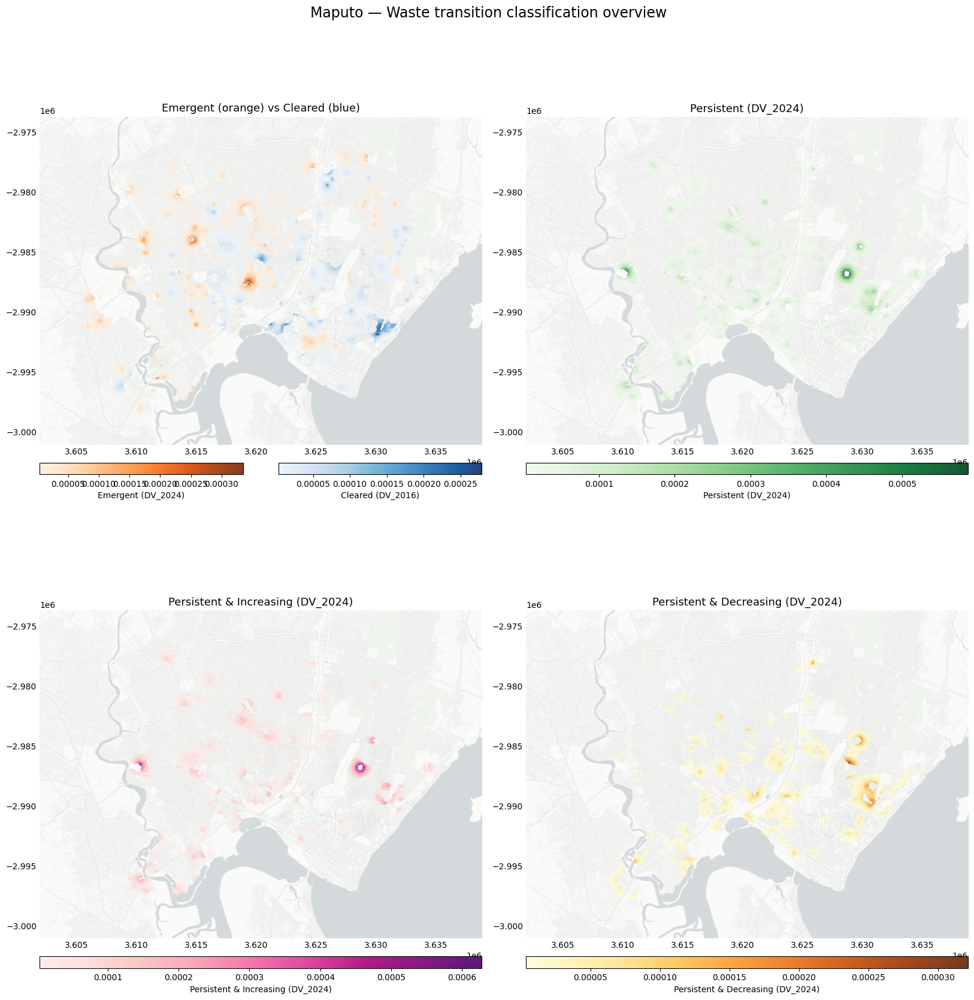

saved: /content/drive/MyDrive/Paper_3/Processing/DV/Combined/Maputo/Maputo_classification_overview.png


In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import contextily as ctx
import math
import os
from pyproj import CRS, Transformer
import matplotlib.font_manager as fm
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

BASE = "/content/drive/MyDrive/Paper_3/Processing/DV"
OUT_BASE = f"{BASE}/Combined"

GRIDSIZE = 300

CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

oranges_trunc = mcolors.ListedColormap(plt.cm.Oranges(np.linspace(0.05, 1, 256)))
blues_trunc   = mcolors.ListedColormap(plt.cm.Blues(np.linspace(0.05, 1, 256)))
greens_trunc  = mcolors.ListedColormap(plt.cm.Greens(np.linspace(0.05, 1, 256)))
magenta_trunc = mcolors.ListedColormap(plt.cm.RdPu(np.linspace(0.05, 1, 256)))
yellows_trunc = mcolors.ListedColormap(plt.cm.YlOrBr(np.linspace(0.05, 1, 256)))

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

def to_web_mercator(sub_df, epsg):
    g = gpd.GeoDataFrame(
        sub_df, geometry=gpd.points_from_xy(sub_df.longitude, sub_df.latitude), crs=4326
    ).to_crs(epsg).to_crs(3857)
    if len(g) > 100000:
        g = g.sample(100000, random_state=42)
    return g

def add_bottom_colorbar(ax, hb, label, x0=0.0, width=1.0, y_offset=-0.09, height=0.035):
    cax = ax.inset_axes([x0, y_offset, width, height])
    fig = ax.get_figure()
    fig.colorbar(hb, cax=cax, orientation="horizontal", label=label)

def plot_single_panel(ax, gdf, color_col, cmap, title, bounds):
    xmin, ymin, xmax, ymax = bounds
    padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)

    if len(gdf) == 0:
        ax.set_title(f"{title} (no data)", fontsize=12)
        return
    hb = ax.hexbin(gdf.geometry.x, gdf.geometry.y, C=gdf[color_col],
                    reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1,
                    linewidths=0, alpha=0.9, cmap=cmap, zorder=6)
    add_bottom_colorbar(ax, hb, title)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)
    ax.set_title(title, fontsize=13)

def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =====================================================================
# MAPUTO
# =====================================================================

city = "Maputo"
c = city.lower()
df = pd.read_csv(f"{OUT_BASE}/{city}/{c}_grid30m_combined.csv")

epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())

emergent   = df[df["category"] == "Emergent"].copy()
cleared    = df[df["category"] == "Cleared"].copy()
persistent = df[df["category"].isin(["Increase", "Decrease"])].copy()
increasing = df[df["category"] == "Increase"].copy()
decreasing = df[df["category"] == "Decrease"].copy()

gdf_em = to_web_mercator(emergent, epsg)
gdf_cl = to_web_mercator(cleared, epsg)
gdf_pe = to_web_mercator(persistent, epsg)
gdf_in = to_web_mercator(increasing, epsg)
gdf_de = to_web_mercator(decreasing, epsg)

all_gdf = pd.concat([gdf_em[["geometry"]], gdf_cl[["geometry"]]])
xmin, ymin, xmax, ymax = all_gdf.total_bounds
padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12

fig, axes = plt.subplots(2, 2, figsize=(20, 20))

# --- Panel 1: Emergent vs Cleared (two colour scales, side-by-side bottom bars) ---
ax = axes[0, 0]
ax.set_xlim(xmin - padx, xmax + padx); ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect("equal", adjustable="box")
ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)
if len(gdf_em):
    hb1 = ax.hexbin(gdf_em.geometry.x, gdf_em.geometry.y, C=gdf_em["DV_2024"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=oranges_trunc, zorder=6)
    add_bottom_colorbar(ax, hb1, "Emergent (DV_2024)", x0=0.0, width=0.46)
if len(gdf_cl):
    hb2 = ax.hexbin(gdf_cl.geometry.x, gdf_cl.geometry.y, C=gdf_cl["DV_2016"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=blues_trunc, zorder=6)
    add_bottom_colorbar(ax, hb2, "Cleared (DV_2016)", x0=0.54, width=0.46)
for spine in ax.spines.values(): spine.set_visible(False)
ax.tick_params(axis="both", which="both", length=0)
ax.set_title("Emergent (orange) vs Cleared (blue)", fontsize=13)

# --- Panel 2: Persistent ---
plot_single_panel(axes[0, 1], gdf_pe, "DV_2024", greens_trunc, "Persistent (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 3: Persistent & Increasing ---
plot_single_panel(axes[1, 0], gdf_in, "DV_2024", magenta_trunc, "Persistent & Increasing (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 4: Persistent & Decreasing ---
plot_single_panel(axes[1, 1], gdf_de, "DV_2024", yellows_trunc, "Persistent & Decreasing (DV_2024)", (xmin, ymin, xmax, ymax))

fig.suptitle(f"{city} — Waste transition classification overview", fontsize=17, y=0.93)
plt.subplots_adjust(hspace=0.15, wspace=0.1)

out_dir = f"{OUT_BASE}/{city}"
os.makedirs(out_dir, exist_ok=True)
out_fig = f"{out_dir}/{city}_classification_overview.png"
plt.savefig(out_fig, dpi=250, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved: {out_fig}")

##Nairobi

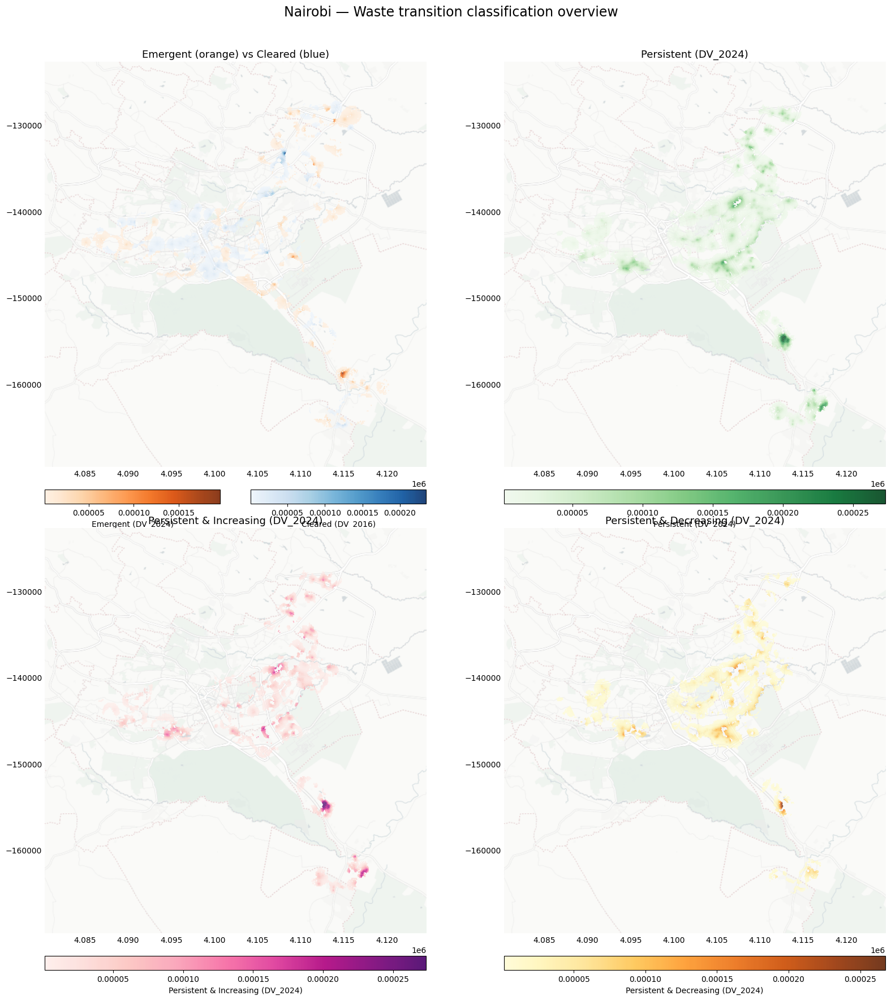

saved: /content/drive/MyDrive/Paper_3/Processing/DV/Combined/Nairobi/Nairobi_classification_overview.png


In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import contextily as ctx
import math
import os
from pyproj import CRS, Transformer
import matplotlib.font_manager as fm
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

BASE = "/content/drive/MyDrive/Paper_3/Processing/DV"
OUT_BASE = f"{BASE}/Combined"

GRIDSIZE = 300

CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

oranges_trunc = mcolors.ListedColormap(plt.cm.Oranges(np.linspace(0.05, 1, 256)))
blues_trunc   = mcolors.ListedColormap(plt.cm.Blues(np.linspace(0.05, 1, 256)))
greens_trunc  = mcolors.ListedColormap(plt.cm.Greens(np.linspace(0.05, 1, 256)))
magenta_trunc = mcolors.ListedColormap(plt.cm.RdPu(np.linspace(0.05, 1, 256)))
yellows_trunc = mcolors.ListedColormap(plt.cm.YlOrBr(np.linspace(0.05, 1, 256)))

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

def to_web_mercator(sub_df, epsg):
    g = gpd.GeoDataFrame(
        sub_df, geometry=gpd.points_from_xy(sub_df.longitude, sub_df.latitude), crs=4326
    ).to_crs(epsg).to_crs(3857)
    if len(g) > 100000:
        g = g.sample(100000, random_state=42)
    return g

def add_bottom_colorbar(ax, hb, label, x0=0.0, width=1.0, y_offset=-0.09, height=0.035):
    cax = ax.inset_axes([x0, y_offset, width, height])
    fig = ax.get_figure()
    fig.colorbar(hb, cax=cax, orientation="horizontal", label=label)

def plot_single_panel(ax, gdf, color_col, cmap, title, bounds):
    xmin, ymin, xmax, ymax = bounds
    padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)

    if len(gdf) == 0:
        ax.set_title(f"{title} (no data)", fontsize=12)
        return
    hb = ax.hexbin(gdf.geometry.x, gdf.geometry.y, C=gdf[color_col],
                    reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1,
                    linewidths=0, alpha=0.9, cmap=cmap, zorder=6)
    add_bottom_colorbar(ax, hb, title)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)
    ax.set_title(title, fontsize=13)

def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =====================================================================
# NAIROBI
# =====================================================================

city = "Nairobi"
c = city.lower()
df = pd.read_csv(f"{OUT_BASE}/{city}/{c}_grid30m_combined.csv")

epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())

emergent   = df[df["category"] == "Emergent"].copy()
cleared    = df[df["category"] == "Cleared"].copy()
persistent = df[df["category"].isin(["Increase", "Decrease"])].copy()
increasing = df[df["category"] == "Increase"].copy()
decreasing = df[df["category"] == "Decrease"].copy()

gdf_em = to_web_mercator(emergent, epsg)
gdf_cl = to_web_mercator(cleared, epsg)
gdf_pe = to_web_mercator(persistent, epsg)
gdf_in = to_web_mercator(increasing, epsg)
gdf_de = to_web_mercator(decreasing, epsg)

all_gdf = pd.concat([gdf_em[["geometry"]], gdf_cl[["geometry"]]])
xmin, ymin, xmax, ymax = all_gdf.total_bounds
padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.12

fig, axes = plt.subplots(2, 2, figsize=(20, 20))

# --- Panel 1: Emergent vs Cleared (two colour scales, side-by-side bottom bars) ---
ax = axes[0, 0]
ax.set_xlim(xmin - padx, xmax + padx); ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect("equal", adjustable="box")
ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels, attribution=False, zorder=0)
if len(gdf_em):
    hb1 = ax.hexbin(gdf_em.geometry.x, gdf_em.geometry.y, C=gdf_em["DV_2024"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=oranges_trunc, zorder=6)
    add_bottom_colorbar(ax, hb1, "Emergent (DV_2024)", x0=0.0, width=0.46)
if len(gdf_cl):
    hb2 = ax.hexbin(gdf_cl.geometry.x, gdf_cl.geometry.y, C=gdf_cl["DV_2016"],
                     reduce_C_function=np.mean, gridsize=GRIDSIZE, mincnt=1, linewidths=0,
                     alpha=0.9, cmap=blues_trunc, zorder=6)
    add_bottom_colorbar(ax, hb2, "Cleared (DV_2016)", x0=0.54, width=0.46)
for spine in ax.spines.values(): spine.set_visible(False)
ax.tick_params(axis="both", which="both", length=0)
ax.set_title("Emergent (orange) vs Cleared (blue)", fontsize=13)

# --- Panel 2: Persistent ---
plot_single_panel(axes[0, 1], gdf_pe, "DV_2024", greens_trunc, "Persistent (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 3: Persistent & Increasing ---
plot_single_panel(axes[1, 0], gdf_in, "DV_2024", magenta_trunc, "Persistent & Increasing (DV_2024)", (xmin, ymin, xmax, ymax))

# --- Panel 4: Persistent & Decreasing ---
plot_single_panel(axes[1, 1], gdf_de, "DV_2024", yellows_trunc, "Persistent & Decreasing (DV_2024)", (xmin, ymin, xmax, ymax))

fig.suptitle(f"{city} — Waste transition classification overview", fontsize=17, y=0.93)
plt.subplots_adjust(hspace=0.15, wspace=0.1)

out_dir = f"{OUT_BASE}/{city}"
os.makedirs(out_dir, exist_ok=True)
out_fig = f"{out_dir}/{city}_classification_overview.png"
plt.savefig(out_fig, dpi=250, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved: {out_fig}")